# How we process the station–ERA5-Land data

This notebook follows the data from the saved station–grid matches to the screened
temperature sample and the covariates used in our analyses. It explains **what each
step changes, why it exists, how many observations it removes, and what remains unresolved**.

Our outcome is

$$
r_{s,t}=T^{\mathrm{station}}_{\max,s,t}-T^{\mathrm{ERA5\text{-}Land}}_{\max,s,t}.
$$

Temperatures and residuals are in °C. A positive residual means ERA5-Land is cooler
than the station observation. These are daily maximum temperatures.

**Scope.** Running all cells reads the existing local release and audit products. It
does not download raw data, rebuild datasets, change screening thresholds, or write
analysis outputs. The displayed outputs are a snapshot of the verified release;
rerun the notebook after rebuilding the data. Saved tables can be read without the
large local inputs.

The implementation remains in `py.cleaning`, `py.temperature_quality`,
`py.covariates`, `py.scripts.audit_cleaning`, and `py.scripts.build_clean_dataset`.
This notebook is an executable explanation and audit, not a second dataset builder.

**Reading order:** inputs and provenance → raw matching → processing audit →
temperature selection → observation windows → covariates and NDVI → analysis samples
→ comparison with the earlier workflow → release checks and reproduction.


## 1. Environment and required local products

Use the repository environment, with the repository package installed. For example,
from the repository root:

```bash
uv sync --locked
tmux new-session -s era5-data-notebook 'uv run --with jupyterlab --with ipykernel jupyter lab src/py/notebooks/data_processing.ipynb'
```

Stop the Jupyter server when finished so its dedicated tmux session ends. Select the
Python kernel from that environment. The notebook uses `py.paths`, so dataset paths
do not depend on the notebook's working directory. Large datasets are local and are
not installed by `uv sync` or included in a plain Git clone.

The checks below use the saved Parquet files and compact audit CSV/JSON files.
Re-extracting the original station records, NetCDF values and raster pixels requires
the source datasets described later; those expensive source checks are not repeated here.


In [1]:
import hashlib as Hashlib
import html as Html
import json as Json
import platform as Platform
import zipfile as Zipfile
from datetime import datetime as Datetime, timezone as Timezone
from pathlib import Path

import altair as Alt
import polars as Pl
import vl_convert as Vlc
from IPython.display import HTML as HtmlOutput, Markdown, display as Display

from py.cleaning import FeatureRows
from py.paths import AnalysisDataDirectory, ProjectRoot

CleanDirectory = AnalysisDataDirectory / "clean"
AuditDirectory = AnalysisDataDirectory / "cleaning_audit"
Checks = []


def Check(Name, Condition, Detail=""):
    Passed = bool(Condition)
    Checks.append({"check": Name, "passed": Passed, "detail": str(Detail)})
    if not Passed:
        raise AssertionError(f"{Name}: {Detail}")


def Digest(File):
    with File.open("rb") as Stream:
        return Hashlib.file_digest(Stream, "sha256").hexdigest()


def ShowTable(Frame):
    def Format(Value):
        if Value is None:
            return ""
        if isinstance(Value, bool):
            return str(Value)
        if isinstance(Value, int):
            return f"{Value:,}"
        if isinstance(Value, float):
            return f"{Value:,.4f}"
        return Html.escape(str(Value))

    Header = "".join(f"<th>{Html.escape(Name)}</th>" for Name in Frame.columns)
    Rows = "".join(
        "<tr>" + "".join(f"<td>{Format(Value)}</td>" for Value in Row) + "</tr>"
        for Row in Frame.iter_rows()
    )
    Display(HtmlOutput(f"<table><thead><tr>{Header}</tr></thead><tbody>{Rows}</tbody></table>"))


def ShowChart(Chart):
    Specification = Chart.configure_view(stroke=None).to_dict()
    Display({"image/svg+xml": Vlc.vegalite_to_svg(Specification)}, raw=True)


Required = [
    "residuals.parquet", "residuals_cleaned.parquet",
    "clean/analysis.parquet", "clean/temperature_pairs.parquet",
    "clean/temperature_pairs_utc.parquet", "clean/excluded_pairs.parquet",
    "clean/observation_sources.parquet", "clean/summary.json",
    "clean/exclusion_counts.csv", "clean/era5_full_checks.csv",
    "clean/temperature_review.csv", "clean/station_quality.csv",
    "clean/observation_windows.csv", "clean/ndvi_backtest.csv",
    "clean/ndvi_sensitivity.csv", "cleaning_audit/summary.json",
]
Missing = [Name for Name in Required if not (AnalysisDataDirectory / Name).is_file()]
if Missing:
    raise FileNotFoundError(
        "Restore the saved release products listed in README.md before running this notebook:\n"
        + "\n".join(Missing)
    )

Summary = Json.loads((CleanDirectory / "summary.json").read_text())
Audit = Json.loads((AuditDirectory / "summary.json").read_text())
Raw = Pl.scan_parquet(AnalysisDataDirectory / "residuals.parquet")
Intermediate = Pl.scan_parquet(AnalysisDataDirectory / "residuals_cleaned.parquet")
Clean = Pl.scan_parquet(CleanDirectory / "analysis.parquet")
Core = Pl.scan_parquet(CleanDirectory / "temperature_pairs.parquet")
Utc = Pl.scan_parquet(CleanDirectory / "temperature_pairs_utc.parquet")
Excluded = Pl.scan_parquet(CleanDirectory / "excluded_pairs.parquet")
Sources = Pl.scan_parquet(CleanDirectory / "observation_sources.parquet")
ExclusionCounts = Pl.read_csv(CleanDirectory / "exclusion_counts.csv")
EraChecks = Pl.read_csv(CleanDirectory / "era5_full_checks.csv")
Review = Pl.read_csv(CleanDirectory / "temperature_review.csv", try_parse_dates=True)
StationQuality = Pl.read_csv(CleanDirectory / "station_quality.csv")
SavedWindows = Pl.read_csv(CleanDirectory / "observation_windows.csv")

Display(Markdown(
    f"Run time: **{Datetime.now(Timezone.utc).isoformat(timespec='seconds')}**. "
    f"Python {Platform.python_version()}, Polars {Pl.__version__}."
))


Run time: **2026-11-16T16:20:27+00:00**. Python 3.11.13, Polars 1.36.1.

## 2. Verify which release we are describing

Counts alone cannot identify a dataset. We verify SHA-256 hashes for the selected
input, the intermediate audit output, and all five final Parquet products. We also
check the link between the processing-audit manifest and the final release manifest.
If any file has changed, this notebook stops instead of presenting stale release claims.


In [2]:
ExpectedHashes = {
    "residuals.parquet": Summary["raw_input_sha256"],
    "residuals_cleaned.parquet": Summary["input_sha256"],
}
ExpectedHashes.update({
    f"clean/{Path(Name).name}": Value for Name, Value in Summary["artifacts"].items()
})
HashRows = []
for Name, Expected in ExpectedHashes.items():
    Actual = Digest(AnalysisDataDirectory / Name)
    Check(f"SHA-256: {Name}", Actual == Expected)
    HashRows.append({"file": Name, "sha256": Actual, "matches_manifest": Actual == Expected})
Check("Audit input links to raw release", Audit["input_sha256"] == Summary["raw_input_sha256"])
Check("Audit output links to final-build input", Audit["cleaned_data_sha256"] == Summary["input_sha256"])
Check("Analysis hash matches artifact manifest", ExpectedHashes["clean/analysis.parquet"] == Summary["cleaned_data_sha256"])
ShowTable(Pl.DataFrame(HashRows))

ReleaseStats = Clean.select(
    Pl.len().alias("observations"),
    Pl.col("STAID").n_unique().alias("nominal_station_ids"),
    Pl.col("SOUID").n_unique().alias("source_ids"),
    Pl.col("date").min().alias("first_date"),
    Pl.col("date").max().alias("last_date"),
    Pl.col("residual").mean().alias("mean_residual_c"),
).collect()
ShowTable(ReleaseStats)


file,sha256,matches_manifest
residuals.parquet,cb172ba533937ac58b5d75ca4f210e6329131256d7c87e8bd8b59d6a83edadff,True
residuals_cleaned.parquet,e833a311a3efa4780696e90f7684f270784eb8959a880119228c6afa2c1d3682,True
clean/temperature_pairs.parquet,8e3e01ce4ea44378825db5f0152230498259bfc84aba88e1a1ec543c9dc69e40,True
clean/temperature_pairs_utc.parquet,82c59fba8e824c269ba1993d048477ae618235c8108d1e92cdc0f803f4485d48,True
clean/analysis.parquet,9c6aa07f0b786d9e66ab5f3f4fda9f56b106eee45711d8fa0c8197f771d47561,True
clean/excluded_pairs.parquet,9e403503fbcfd4f353b4f909d09dcb3739df7150eb7a5ea63841724bce752967,True
clean/observation_sources.parquet,6864ab942721b7601f192bbc0fd5c731bdff7649552549b55b285a279ff2e7e1,True


observations,nominal_station_ids,source_ids,first_date,last_date,mean_residual_c
"6,958,414","4,217","4,561",2020-01-01 00:00:00,2025-08-31 00:00:00,1.5808


## 3. What the inputs represent

| Input | Use and units |
|:---|:---|
| ECA&D blended TX files | Daily maximum station temperature, stored in tenths of °C. Retain `Q_TX = 0`, reject `TX = -9999`, and use `TX / 10`. |
| Supplied ERA5-Land daily NetCDFs | Daily maximum of hourly 2 m temperature on a 0.1° grid; subtract 273.15 from Kelvin. Supplied daily wind-component and precipitation products are also extracted. |
| ECA&D station and source metadata | Nominal station identity, actual source identity, coordinates, elevation and observation-window code. |
| Seasonal NDVI rasters | Seasonal vegetation values. Valid encoded values 0–254 map to −1…1 using `value / 254 * 2 - 1`; nodata remains missing. |
| GHS-SMOD 2020 raster | Fixed-reference urbanization classes, sampled in the raster's coordinate system. |
| Natural Earth 1:10 million coastline | Approximate distance to the ocean coastline; the Caspian ring is excluded. |

### Raw matching and the selected starting file

The extraction notebook joins valid station records to available ERA5 dates and uses
the nearest latitude/longitude grid cell. The saved legacy matches include substitutions
onto another land cell where the nearest ERA5 temperature series was missing. The
screened baseline later excludes these substitutions.

The current raw notebook can generate a **candidate** `residuals_rebuilt.parquet`.
Its nearest-land fallback uses geodesic distance; that candidate must be reviewed
before replacing the selected `residuals.parquet`. A new raw build is not assumed to
be byte-identical to the saved input analysed here.

The row count below starts **after** initial quality filtering, date matching and
station-file availability. It is not the total number of observations downloaded from ECA&D.

### Two station identifiers

`STAID` identifies a nominal blended series. `SOUID` identifies the source of an actual
observation. Several nominal series can borrow the same source observation, and one
nominal series can use different sources over time. Consequently, a nominal station
count is not automatically a count of independent physical instruments.

Source metadata are joined to every `(STAID, date)`. In this release some source
metadata IDs require an inferred offset of +100000; direct and offset IDs are both
preserved. Ambiguous matches stop the build. The provider mapping still merits confirmation.


In [3]:
InputCounts = []
for Label, Frame in [("Selected matched input", Raw), ("After processing audit", Intermediate)]:
    Stats = Frame.select(
        Pl.len().alias("observations"),
        Pl.col("STAID").n_unique().alias("nominal_station_ids"),
        Pl.col("date").min().alias("first_date"),
        Pl.col("date").max().alias("last_date"),
    ).collect().row(0, named=True)
    InputCounts.append({"stage": Label, **Stats})
Check("Raw row count", InputCounts[0]["observations"] == Audit["input_rows"])
Check("Raw station count", InputCounts[0]["nominal_station_ids"] == Audit["input_stations"])
Check("Intermediate row count", InputCounts[1]["observations"] == Audit["cleaned_rows"] == Summary["input_rows"])
Check("Intermediate station count", InputCounts[1]["nominal_station_ids"] == Audit["cleaned_stations"])
ShowTable(Pl.DataFrame(InputCounts))
ShowTable(Sources.group_by("source_metadata_id_offset").agg(
    Pl.len().alias("observations"), Pl.col("SOUID").n_unique().alias("sources")
).sort("source_metadata_id_offset").collect())


stage,observations,nominal_station_ids,first_date,last_date
Selected matched input,"10,467,039","6,064",2020-01-01 00:00:00,2025-08-31 00:00:00
After processing audit,"10,024,790","5,710",2020-01-01 00:00:00,2025-08-31 00:00:00


source_metadata_id_offset,observations,sources
0,"425,327",569
"100,000","9,599,463","4,589"


## 4. The processing audit: values, grid footprint and intermediate covariates

`py.scripts.audit_cleaning` preserves the selected input and produces
`residuals_cleaned.parquet`. It checks duplicate station-days, finite core values and
the identity `residual = station_celsius - era5_celsius`.

Stations outside the supplied ERA5 grid footprint are removed. The footprint includes
half a grid-cell margin: longitude **−25.05° to 40.95°**, latitude **34.95° to 69.95°**.
Without this check, nearest-coordinate matching can snap an outside station onto an edge cell.

The audit masks elevation sentinels (−999 and −9999), unsupported old coast distances
and NDVI carried from other years. These are **intermediate** covariate decisions.
The final builder recalculates covariates and applies the authorized seasonal NDVI
carry-forward policy described below. Intermediate NDVI availability must not be used
as the final sample definition.

The production pipeline checks saved station TX values and quality flags against the
source files. The earlier ERA5 audit sampled dates; the final build checks **every
in-grid pair** against the supplied daily temperature, wind and precipitation files.
Here we inspect the saved check results. Agreement verifies extraction and arithmetic
against those files, not instrument accuracy or the upstream daily-aggregation recipe.


In [4]:
Check("Source-temperature audit reports no mismatch", Audit["source_quality_mismatches"] == 0)
Check("Input audit reports no duplicate station-days", Audit["duplicate_station_dates"] == 0)
Check("Full ERA5 audit covers intermediate rows", EraChecks["sampled_station_days"].sum() == Summary["input_rows"])
for Name in EraChecks.columns:
    if Name.endswith("mismatches"):
        Check(f"Full ERA5 audit: {Name}", EraChecks[Name].sum() == 0)
ShowTable(EraChecks)
Display(Markdown(
    f"The initial ERA5 audit sampled **{Audit['era5_checked_station_days']:,}** pairs; "
    f"the final audit covered **{EraChecks['sampled_station_days'].sum():,}** pairs."
))


year,sampled_station_days,temperaturemax_absolute_error,temperature_mismatches,windmax_absolute_error,wind_mismatches,tpmax_absolute_error,tp_mismatches
"2,020","1,827,751",0.0000,0,0.0000,0,0.0000,0
"2,021","1,853,792",0.0000,0,0.0000,0,0.0000,0
"2,022","1,818,528",0.0000,0,0.0000,0,0.0000,0
"2,023","1,816,149",0.0000,0,0.0000,0,0.0000,0
"2,024","1,700,672",0.0000,0,0.0000,0,0.0000,0
"2,025","1,007,898",0.0000,0,0.0000,0,0.0000,0


The initial ERA5 audit sampled **240,384** pairs; the final audit covered **10,024,790** pairs.

## 5. Temperature eligibility, in execution order

After the footprint restriction, `SelectTemperaturePairs` applies these rules in order:

1. **Exclude land-cell substitutions.** A different matching rule can change coastal
   representativeness. This exclusion does not imply that the station is defective.
2. **Quarantine station series using flagged sources.** Screening uses station
   temperatures and their temporal/spatial neighbours, never ERA5 residual magnitude.
3. **Require valid source identity and quality.** Missing provenance stops the production
   build earlier; the selector also has a defensive exclusion rule.
4. **Require agreement of the source location and saved ERA5 cell.** Actual source
   coordinates must select the same nearest cell as the saved match and lie within
   half a grid-cell spacing of it. Otherwise a borrowed observation may be paired with
   a cell selected for the nominal station rather than its source.
5. **Keep one copy per `(SOUID, date)`.** Sort by nominal `STAID` and date, then retain
   the first eligible copy. The smallest eligible nominal ID wins deterministically.

Counts below are **sequential first-reason exclusions**. They are not independent
failure counts. The notebook reconstructs survivor counts from accepted pairs and
the saved exclusion ledger, and checks them against the release.

`clean/excluded_pairs.parquet` contains exclusions from the **second-stage builder**.
The earlier outside-footprint removals are recorded separately in `cleaning_audit/`.
Both stages are needed for the full accounting.


step,removed,retained,nominal_station_ids,percent_of_start
0. Selected matched input,0,"10,467,039","6,064",100.0000
1. Inside grid footprint,"442,249","10,024,790","5,710",95.7748
2. Exclude substituted land cells,"948,022","9,076,768","5,210",86.7176
3. Quarantine flagged series,"72,993","9,003,775","5,159",86.0203
4. Require valid source,0,"9,003,775","5,159",86.0203
5. Require source/grid agreement,"1,093,595","7,910,180","4,685",75.5723
6. Deduplicate source-days,"951,766","6,958,414","4,217",66.4793


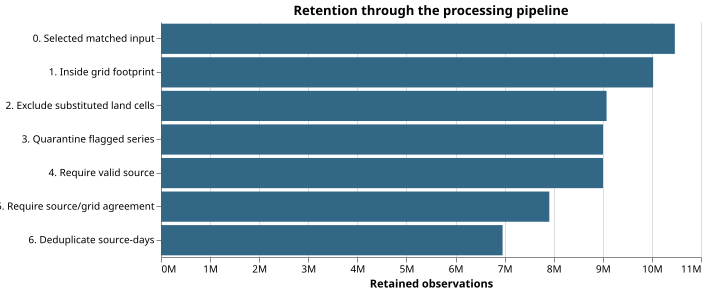

In [5]:
Rules = [
    ("2. Exclude substituted land cells", "era5_land_fallback"),
    ("3. Quarantine flagged series", "station_series_quarantined"),
    ("4. Require valid source", "invalid_observation_source"),
    ("5. Require source/grid agreement", "source_location_grid_mismatch"),
    ("6. Deduplicate source-days", "reused_source_observation"),
]
SavedRemoval = dict(ExclusionCounts.iter_rows())
ActualRemoval = dict(Excluded.group_by("exclusion_reason").len().collect().iter_rows())
Check("Exclusion ledger matches compact counts", ActualRemoval == SavedRemoval)
Check("Exclusion reasons are recognized", set(ActualRemoval).issubset({Reason for Label, Reason in Rules}))

Membership = Pl.concat([
    Core.select("STAID").with_columns(Pl.lit("retained").alias("exclusion_reason")),
    Excluded.select("STAID", "exclusion_reason"),
]).group_by("STAID", "exclusion_reason").len().collect()

SelectionRows = [
    {"step": "0. Selected matched input", "removed": 0,
     "retained": Audit["input_rows"], "nominal_station_ids": Audit["input_stations"]},
    {"step": "1. Inside grid footprint", "removed": Audit["outside_grid_rows"],
     "retained": Audit["cleaned_rows"], "nominal_station_ids": Audit["cleaned_stations"]},
]
RemovedReasons = []
for Label, Reason in Rules:
    RemovedReasons.append(Reason)
    Remaining = Membership.filter(~Pl.col("exclusion_reason").is_in(RemovedReasons))
    SelectionRows.append({
        "step": Label,
        "removed": SavedRemoval.get(Reason, 0),
        "retained": int(Remaining["len"].sum()),
        "nominal_station_ids": Remaining["STAID"].n_unique(),
    })
Selection = Pl.DataFrame(SelectionRows).with_columns(
    (100 * Pl.col("retained") / Audit["input_rows"]).alias("percent_of_start")
)
for Before, After in zip(SelectionRows, SelectionRows[1:]):
    Check(f"Selection arithmetic: {After['step']}", Before["retained"] - After["removed"] == After["retained"])
Check("Selection reaches final row count", SelectionRows[-1]["retained"] == Summary["cleaned_rows"])
Check("Selection reaches final station count", SelectionRows[-1]["nominal_station_ids"] == Summary["cleaned_stations"])
ShowTable(Selection)
ShowChart(Alt.Chart(Selection).mark_bar(color="#326785").encode(
    x=Alt.X("retained:Q", title="Retained observations", axis=Alt.Axis(format="~s")),
    y=Alt.Y("step:N", sort=Selection["step"].to_list(), title=None, axis=Alt.Axis(labelLimit=300)),
).properties(width=540, height=235, title="Retention through the processing pipeline"))


## 6. What triggers whole-series quarantine?

Station-only screening is performed on unique source-days at their actual locations.
Any of the following marks a source-day for review:

| Rule | Implemented threshold |
|:---|:---|
| Absolute TX range | Outside **[−60, 50] °C**. |
| Isolated temporal spike | More than **20°C above both**, or below both, adjacent calendar days. Both neighbours must exist. |
| Spatial disagreement | More than **20°C** from the same-day median of at least **three** available neighbours. Candidates are among the nearest 64, **15–100 km** away and within **300 m** elevation; at most ten distinct locations are retained. |

The builder finds every nominal series using any flagged source and quarantines its
**entire series**, including unflagged days. These provisional thresholds have not been
calibrated as a climatological QC algorithm. Whole-series quarantine is a scientific
selection choice requiring review, not a mechanical data-format correction.

Missing neighbour coverage does not constitute a passed spatial check. Flag counts
can overlap, and borrowed copies must not be counted as independent source-days.


In [6]:
UniqueReview = Review.unique(subset=["SOUID", "date"]).sort("SOUID", "date")
Quarantined = StationQuality.filter(Pl.col("quarantined"))["STAID"].to_list()
FlaggedSources = UniqueReview["SOUID"].unique().to_list()
SourceQuarantine = Sources.filter(Pl.col("SOUID").is_in(FlaggedSources)).select("STAID").unique().collect()["STAID"].to_list()
Check("Flagged source-day count", len(UniqueReview) == Summary["source_flagged_observations"])
Check("Quarantined station count", len(Quarantined) == Summary["quarantined_stations"])
Check("Quarantine includes all series using flagged sources", set(SourceQuarantine) == set(Quarantined))
ShowTable(Pl.DataFrame([
    {"measure": "Unique flagged source-days", "count": len(UniqueReview)},
    {"measure": "Flagged source IDs", "count": len(FlaggedSources)},
    {"measure": "Quarantined nominal series", "count": len(Quarantined)},
    {"measure": "Intermediate rows without a spatial check", "count": StationQuality["days_without_spatial_check"].sum()},
]))
ShowTable(Pl.DataFrame([
    {"rule": Label, "flagged_source_days": int(UniqueReview[Column].sum())}
    for Label, Column in [
        ("Range", "source_range_flag"),
        ("Temporal spike", "source_spike_flag"),
        ("Spatial disagreement", "source_spatial_flag"),
    ]
]))
ShowTable(UniqueReview.select(
    "SOUID", "date", "station_celsius", "previous_day", "next_day",
    "neighbor_median", "neighbor_count",
).head(8))


measure,count
Unique flagged source-days,313
Flagged source IDs,44
Quarantined nominal series,55
Intermediate rows without a spatial check,"793,902"


rule,flagged_source_days
Range,155
Temporal spike,14
Spatial disagreement,302


SOUID,date,station_celsius,previous_day,next_day,neighbor_median,neighbor_count
"37,317",2024-01-04 00:00:00,-34.9000,,-9.7000,-10.7500,6
"37,428",2021-12-06 00:00:00,-37.3000,-16.0000,-12.9000,-17.3500,10
"37,428",2023-12-27 00:00:00,-22.7000,-8.3000,-23.8000,-2.6500,10
"37,428",2023-12-28 00:00:00,-23.8000,-22.7000,-17.8000,-2.5000,10
"46,472",2022-11-17 00:00:00,8.0000,6.5000,-0.5000,-20.3000,7
"46,472",2022-11-21 00:00:00,2.4000,2.4000,-4.1000,-20.5000,7
"56,365",2022-05-01 00:00:00,0.0000,18.5000,,20.2000,10
"75,531",2023-10-22 00:00:00,45.5000,23.5000,23.5000,20.1000,3


## 7. The retained temperature sample and its coverage

The builder writes `temperature_pairs.parquet` before attaching the final covariates.
`analysis.parquet` must contain exactly the same temperature-pair keys. A missing
NDVI or elevation value does not remove a valid temperature pair from this parent sample.

Yearly and country counts describe the retained sample, not a balanced panel or an
area-weighted sample of Europe. A station ID can occur in multiple years; station
counts across groups are not additive. The last year is partial.


In [7]:
ShowTable(ReleaseStats)
YearCoverage = Clean.group_by(Pl.col("date").dt.year().alias("year")).agg(
    Pl.len().alias("observations"),
    Pl.col("STAID").n_unique().alias("nominal_station_ids"),
    Pl.col("date").min().alias("first_date"),
    Pl.col("date").max().alias("last_date"),
).sort("year").collect()
ShowTable(YearCoverage)
CountryCoverage = Clean.group_by("country").agg(
    Pl.len().alias("observations"), Pl.col("STAID").n_unique().alias("nominal_station_ids")
).with_columns((100 * Pl.col("observations") / Summary["cleaned_rows"]).alias("observation_percent")).sort("observations", descending=True).collect()
Display(Markdown("Largest ten country groups by retained observation count:"))
ShowTable(CountryCoverage.head(10))


observations,nominal_station_ids,source_ids,first_date,last_date,mean_residual_c
"6,958,414","4,217","4,561",2020-01-01 00:00:00,2025-08-31 00:00:00,1.5808


year,observations,nominal_station_ids,first_date,last_date
"2,020","1,286,407","3,791",2020-01-01 00:00:00,2020-12-31 00:00:00
"2,021","1,313,743","3,850",2021-01-01 00:00:00,2021-12-31 00:00:00
"2,022","1,271,299","3,883",2022-01-01 00:00:00,2022-12-31 00:00:00
"2,023","1,265,752","3,693",2023-01-01 00:00:00,2023-12-31 00:00:00
"2,024","1,144,453","3,552",2024-01-01 00:00:00,2024-12-31 00:00:00
"2,025","676,760","3,290",2025-01-01 00:00:00,2025-08-31 00:00:00


Largest ten country groups by retained observation count:

country,observations,nominal_station_ids,observation_percent
Spain,"1,550,587",816,22.2836
Italy,"1,051,991",897,15.1183
Germany,"925,351",460,13.2983
Norway,"704,611",424,10.1260
Austria,"547,504",391,7.8682
Sweden,"420,909",217,6.0489
Finland,"312,269",159,4.4876
Hungary,"261,359",144,3.7560
Poland,"204,949",112,2.9453
Türkiye,"162,925",87,2.3414


## 8. Observation windows: the UTC subset is a separate analysis choice

Matching calendar dates does not establish identical 24-hour measurement intervals.
The main dataset preserves mixed source observation windows. The documented TX3/TX21
00:00–00:00 UTC records also form `temperature_pairs_utc.parquet`.

The table below recomputes both memberships. A nominal ID can appear in both groups
when its source or window changes. Differences in residual means combine timing and
sample-composition differences; they do not isolate a causal effect of window alignment.
Even aligned intervals leave differing sampling frequencies: ERA5 maxima use hourly
samples, whereas station measurement frequencies vary.


In [8]:
WindowSummary = Clean.group_by("utc_day_aligned").agg(
    Pl.len().alias("observations"),
    Pl.col("STAID").n_unique().alias("nominal_station_ids"),
    Pl.col("residual").mean().alias("mean_residual_c"),
).sort("utc_day_aligned", descending=True).collect()
ShowTable(WindowSummary)
WindowDetail = Clean.group_by("observation_window", "utc_day_aligned").agg(
    Pl.len().alias("observations"), Pl.col("STAID").n_unique().alias("stations")
).collect()
Check("Saved observation-window counts", WindowDetail.sort("observation_window", "utc_day_aligned").equals(SavedWindows.sort("observation_window", "utc_day_aligned")))
ShowTable(WindowDetail.sort("observations", descending=True))


utc_day_aligned,observations,nominal_station_ids,mean_residual_c
True,"3,528,147","2,154",1.3604
False,"3,430,267","2,084",1.8075


observation_window,utc_day_aligned,observations,stations
TX3,True,"3,447,720","1,942"
TX2,False,"2,003,822","1,168"
TX20,False,"468,856",379
TX1,False,"233,492",133
TX9,False,"210,731",137
TX7,False,"199,197",417
TX21,True,"80,427",212
TX6,False,"74,553",37
TX14,False,"74,180",37
TX13,False,"54,946",32


## 9. Covariates are added after temperature selection

| Variable | Final processing | Interpretation limit |
|:---|:---|:---|
| `elevation` | Actual source metadata height in metres; −999/−9999 become missing. Preserve `nominal_station_elevation` separately. | A nominal series can change source/elevation over time. |
| `degurba` | Sample 2020 GHS-SMOD at source coordinates after CRS transformation. Unknown codes and nodata stay missing. | Fixed 2020 classification; water cells are excluded only by analyses requiring land classes. |
| `dist_to_sea_km` | Find the nearest coastline point in EPSG:3035, then calculate WGS84 geodesic distance. | Generalized Natural Earth coastline, omitted small islands, and the nearest-point projection limit fine coastal interpretation. |
| `wind` / `mean_wind_vector_mps` | `sqrt(mean(u10)^2 + mean(v10)^2)`, in m/s. | Magnitude of the daily mean vector, not the mean of hourly wind-speed magnitudes. |
| `tp` / `precipitation_proxy_m` | Retain the supplied daily precipitation proxy in metres. | Upstream accumulation/deaccumulation is unresolved. Do not infer a daily total, multiply by 24, or relabel as mm/day. |
| `ndvi` | Sample the contemporaneous seasonal raster or an earlier matching season, with provenance. | Carry-forward is an assumption about persistence; spatial nodata stays missing. |

Spatial covariates use `source_lat`/`source_lon`. Nominal `lat`/`lon` remain in the table
for traceability. Do not assume they are interchangeable when mapping or aggregating.
The table shows per-feature availability in the parent sample. Missingness is handled
by each analysis, rather than a global complete-case drop.


In [9]:
AvailabilityRows = []
for Feature in ["station_celsius", "era5_celsius", "wind", "tp", "elevation", "dist_to_sea_km", "ndvi"]:
    Stats = FeatureRows(Clean, [Feature]).select(
        Pl.len().alias("available_observations"),
        Pl.col("STAID").n_unique().alias("nominal_station_ids"),
    ).collect().row(0, named=True)
    AvailabilityRows.append({"feature": Feature, **Stats,
        "missing_or_nonfinite": Summary["cleaned_rows"] - Stats["available_observations"]})
ShowTable(Pl.DataFrame(AvailabilityRows))
DegurbaCoverage = Clean.group_by("degurba", "degurba_label").agg(
    Pl.len().alias("observations"), Pl.col("STAID").n_unique().alias("nominal_station_ids")
).sort("degurba").collect()
ShowTable(DegurbaCoverage)
Display(Markdown("Station counts across DEGURBA classes can overlap when a nominal series changes source."))


feature,available_observations,nominal_station_ids,missing_or_nonfinite
station_celsius,"6,958,414","4,217",0
era5_celsius,"6,958,414","4,217",0
wind,"6,958,414","4,217",0
tp,"6,958,414","4,217",0
elevation,"6,954,589","4,214","3,825"
dist_to_sea_km,"6,958,414","4,217",0
ndvi,"6,801,065","4,141","157,349"


degurba,degurba_label,observations,nominal_station_ids
10,Water,"31,337",17
11,Very low density rural,"2,532,936","1,641"
12,Low density rural,"2,205,318","1,314"
13,Rural cluster,"537,064",338
21,Suburban,"712,167",433
22,Semi-dense urban cluster,"102,984",66
23,Dense urban cluster,"320,232",227
30,Urban centre,"516,376",312


Station counts across DEGURBA classes can overlap when a nominal series changes source.

## 10. Seasonal NDVI: observed, extrapolated or missing

For each observation date, use the raster covering its season if present. Otherwise,
choose the **latest earlier raster for the same seasonal quarter**. Winter starts in
December of the preceding year for January and February observations. We do not use
future rasters or interpolate between different seasons.

Once the seasonal file is selected, a spatial nodata pixel remains missing; the
algorithm does not search progressively older rasters for a valid pixel.

Each value preserves `ndvi_source_file`, `ndvi_source_start`, `ndvi_source_end`,
`ndvi_years_extrapolated`, `ndvi_is_extrapolated` and `ndvi_method`. The flag describes
available extrapolated values; missing pixels remain labelled `missing`, even if the
chosen file is from an earlier year.


ndvi_method,observations,nominal_station_ids,percent_of_parent
observed_season,"4,927,797","4,013",70.8178
previous_same_season,"1,873,268","3,586",26.9209
missing,"157,349",161,2.2613


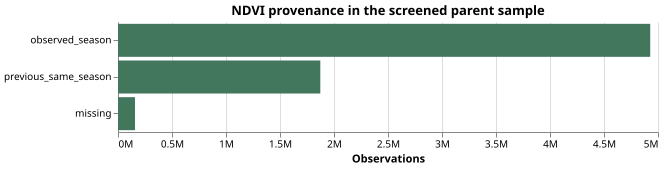

year,ndvi_method,observations
"2,020",missing,"28,754"
"2,020",observed_season,"1,257,653"
"2,021",missing,"28,779"
"2,021",observed_season,"1,284,964"
"2,022",missing,"29,125"
"2,022",observed_season,"1,242,174"
"2,023",missing,"29,942"
"2,023",observed_season,"1,143,006"
"2,023",previous_same_season,"92,804"
"2,024",missing,"29,269"


Distinct seasonal mappings with available NDVI, showing the latest twelve date ranges:

ndvi_source_file,ndvi_source_start,ndvi_source_end,ndvi_years_extrapolated,ndvi_method,first_observation,last_observation,observations
ndvi_2022-09-01_2022-12-01.tif,2022-09-01,2022-12-01,0,observed_season,2022-09-01 00:00:00,2022-11-30 00:00:00,"321,409"
ndvi_2022-12-01_2023-03-01.tif,2022-12-01,2023-03-01,0,observed_season,2022-12-01 00:00:00,2023-02-28 00:00:00,"309,869"
ndvi_2023-03-01_2023-06-01.tif,2023-03-01,2023-06-01,0,observed_season,2023-03-01 00:00:00,2023-05-31 00:00:00,"317,890"
ndvi_2023-06-01_2023-09-01.tif,2023-06-01,2023-09-01,0,observed_season,2023-06-01 00:00:00,2023-08-31 00:00:00,"317,744"
ndvi_2023-09-01_2023-12-01.tif,2023-09-01,2023-12-01,0,observed_season,2023-09-01 00:00:00,2023-11-30 00:00:00,"303,940"
ndvi_2022-12-01_2023-03-01.tif,2022-12-01,2023-03-01,1,previous_same_season,2023-12-01 00:00:00,2024-02-29 00:00:00,"285,911"
ndvi_2023-03-01_2023-06-01.tif,2023-03-01,2023-06-01,1,previous_same_season,2024-03-01 00:00:00,2024-05-31 00:00:00,"294,795"
ndvi_2023-06-01_2023-09-01.tif,2023-06-01,2023-09-01,1,previous_same_season,2024-06-01 00:00:00,2024-08-31 00:00:00,"278,312"
ndvi_2023-09-01_2023-12-01.tif,2023-09-01,2023-12-01,1,previous_same_season,2024-09-01 00:00:00,2024-11-30 00:00:00,"262,359"
ndvi_2022-12-01_2023-03-01.tif,2022-12-01,2023-03-01,2,previous_same_season,2024-12-01 00:00:00,2025-02-28 00:00:00,"257,849"


In [10]:
NdviCoverage = Clean.group_by("ndvi_method").agg(
    Pl.len().alias("observations"), Pl.col("STAID").n_unique().alias("nominal_station_ids")
).with_columns((100 * Pl.col("observations") / Summary["cleaned_rows"]).alias("percent_of_parent")).sort("observations", descending=True).collect()
NdviCounts = dict(NdviCoverage.select("ndvi_method", "observations").iter_rows())
for Method, Key in [
    ("observed_season", "ndvi_observed_rows"),
    ("previous_same_season", "ndvi_extrapolated_rows"),
    ("missing", "ndvi_missing_rows"),
]:
    Check(f"NDVI count: {Method}", NdviCounts.get(Method, 0) == Summary[Key])
ShowTable(NdviCoverage)
ShowChart(Alt.Chart(NdviCoverage).mark_bar(color="#42775e").encode(
    x=Alt.X("observations:Q", title="Observations", axis=Alt.Axis(format="~s")),
    y=Alt.Y("ndvi_method:N", sort=NdviCoverage["ndvi_method"].to_list(), title=None),
).properties(width=540, height=110, title="NDVI provenance in the screened parent sample"))

NdviByYear = Clean.group_by(
    Pl.col("date").dt.year().alias("year"), "ndvi_method"
).len(name="observations").sort("year", "ndvi_method").collect()
ShowTable(NdviByYear)
Display(Markdown("Distinct seasonal mappings with available NDVI, showing the latest twelve date ranges:"))
SeasonMappings = Clean.filter(Pl.col("ndvi").is_finite()).group_by(
    "ndvi_source_file", "ndvi_source_start", "ndvi_source_end", "ndvi_years_extrapolated", "ndvi_method"
).agg(
    Pl.col("date").min().alias("first_observation"),
    Pl.col("date").max().alias("last_observation"),
    Pl.len().alias("observations"),
).sort("first_observation").collect()
ShowTable(SeasonMappings.tail(12))


### Check the carry-forward assumption where observations exist

The saved backtest compares observed source-season NDVI with the same source and
season one or two years earlier. Its error is observed minus carried-forward NDVI.
This measures historical persistence error, not uncertainty coverage for future values.
The lag-one and lag-two samples differ.

The sensitivity table compares residual profiles for observed-only NDVI against
observed plus extrapolated NDVI using common fixed-width NDVI bins. These samples
also differ in years and composition, so their differences are not pure imputation effects.


In [11]:
ShowTable(Pl.read_csv(CleanDirectory / "ndvi_backtest.csv"))
ShowTable(Pl.read_csv(CleanDirectory / "ndvi_sensitivity.csv"))


years_carried,station_seasons,mae,rmse,mean_error_observed_minus_proxy
1,"40,237",0.0730,0.1081,-0.0043
2,"26,418",0.0712,0.1047,-0.0047


ndvi_bin_lower,observations,stations,mean_residual,sample
-0.8000,575,6,-0.5076,observed_only
-0.6000,"2,821",13,1.0154,observed_only
-0.4000,"10,956",49,1.9596,observed_only
-0.2000,"169,154",649,1.6776,observed_only
0.0000,"701,971","2,024",1.6292,observed_only
0.2000,"1,294,203","3,160",1.5690,observed_only
0.4000,"1,606,621","3,249",1.5835,observed_only
0.6000,"1,041,348","2,310",1.6259,observed_only
0.8000,"100,148",485,1.5337,observed_only
-0.8000,943,7,0.5653,observed_plus_extrapolated


## 11. Which sample does each analysis use?

There is one screened **parent** sample, followed by explicit analysis-specific
filters. The table is recomputed from the actual file. It includes the multivariable
sample used by the supplied v3 analysis script; this notebook does not fit those models.

The OLS rule requires available elevation and NDVI plus a non-water DEGURBA class.
The correction-model benchmark instead uses the full parent sample and handles missing
predictors within the model. Its spline/tree training cap of 800,000 rows per fold does
not change the denominator of its full out-of-fold evaluation.

For fair method comparisons, hold rows and bin boundaries fixed before comparing
algorithms. Main figures use per-feature availability; joint plots need the intersection
of their required covariates. A single reported N should not be copied to every result.


In [12]:
SampleDefinitions = [
    ("Main temperature sample / correction-model evaluation", Pl.lit(True)),
    ("UTC-window sensitivity", Pl.col("utc_day_aligned")),
    ("Elevation available", Pl.col("elevation").is_finite()),
    ("NDVI available, including extrapolation", Pl.col("ndvi").is_finite()),
    ("NDVI contemporaneous only", Pl.col("ndvi").is_finite() & ~Pl.col("ndvi_is_extrapolated")),
    ("Land DEGURBA", Pl.col("degurba").is_not_null() & (Pl.col("degurba") != 10)),
    ("V3 multivariable OLS", Pl.col("elevation").is_finite()
        & ~Pl.col("elevation").is_in([-9999.0, -999.0])
        & Pl.col("ndvi").is_finite() & Pl.col("degurba").is_not_null()
        & (Pl.col("degurba") != 10)),
]
SampleRows = []
for Label, Predicate in SampleDefinitions:
    Stats = Clean.filter(Predicate).select(
        Pl.len().alias("observations"),
        Pl.col("STAID").n_unique().alias("nominal_station_ids"),
        Pl.col("residual").mean().alias("mean_residual_c"),
    ).collect().row(0, named=True)
    SampleRows.append({"sample": Label, **Stats})
ShowTable(Pl.DataFrame(SampleRows))


sample,observations,nominal_station_ids,mean_residual_c
Main temperature sample / correction-model evaluation,"6,958,414","4,217",1.5808
UTC-window sensitivity,"3,528,147","2,154",1.3604
Elevation available,"6,954,589","4,214",1.5809
"NDVI available, including extrapolation","6,801,065","4,141",1.5745
NDVI contemporaneous only,"4,927,797","4,013",1.5977
Land DEGURBA,"6,927,077","4,200",1.5771
V3 multivariable OLS,"6,766,806","4,121",1.5708


## 12. How this differs from the earlier notebooks and the delivered ZIP

The original residual notebook at commit `5ee9293` loaded `residuals.parquet` and
applied `.drop_nulls()` across all columns. Below we replay **that selection rule on
the saved input**; this is not an independent reproduction of the historical run.

| Earlier workflow | Current screened workflow |
|:---|:---|
| Global complete-case drop tied temperature inclusion to every covariate. | Temperature eligibility is defined first; covariate availability is analysis-specific. |
| Land fallback and source borrowing could remain in the analysed pairs. | Exclude fallback/source-cell mismatches and keep one copy per source-day. |
| Quality flag filtering without the later station-only quarantine policy. | Add provisional source-level screening and quarantine associated nominal series. |
| Seasonal NDVI carry-forward was already used. | Carry-forward now preserves source dates, lag, method and a flag; spatial sampling uses source locations. |
| A calendar-date join obscured differing observation windows. | Preserve window metadata and provide a documented UTC subset. |

The supplied v3 scripts add downstream analyses. At review time their seven core
preprocessing files matched this working tree, and their manifest named the same
analysis hash. The optional ZIP check below verifies that statement against the local
archive if it is available. The ZIP contains no Parquet dataset, so a declared hash
is not independent evidence of which file a remote analysis actually read.


In [13]:
Legacy = Raw.drop_nulls()
LegacyStats = Legacy.select(
    Pl.len().alias("observations"), Pl.col("STAID").n_unique().alias("nominal_station_ids"),
    Pl.col("residual").mean().alias("mean_residual_c"),
).collect().row(0, named=True)
ShowTable(Pl.DataFrame([
    {"selection": "Historical drop_nulls rule on saved input", **LegacyStats},
    {"selection": "Current screened parent", **{Key: ReleaseStats[Key][0] for Key in LegacyStats}},
]))
Overlap = Legacy.select("STAID", "date").join(
    Clean.select("STAID", "date"), on=["STAID", "date"], how="semi"
).select(Pl.len()).collect().item()
ShowTable(Pl.DataFrame([
    {"membership": "In both selections", "observations": Overlap},
    {"membership": "Historical rule only", "observations": LegacyStats["observations"] - Overlap},
    {"membership": "Screened parent only", "observations": Summary["cleaned_rows"] - Overlap},
]))

ZipPath = ProjectRoot / "ERA5_resid_v3_code.zip"
if ZipPath.exists():
    PreprocessingFiles = [
        "src/py/cleaning.py", "src/py/temperature_quality.py", "src/py/covariates.py",
        "src/py/scripts/audit_cleaning.py", "src/py/scripts/build_clean_dataset.py",
        "src/py/notebooks/temp_resid.py", "src/py/notebooks/cleaning_process.py",
    ]
    with Zipfile.ZipFile(ZipPath) as Archive:
        Prefix = "ERA5_resid/"
        ZipRows = [{"file": Name, "identical_to_working_tree": Archive.read(Prefix + Name) == (ProjectRoot / Name).read_bytes()}
                   for Name in PreprocessingFiles]
        ZipSummary = Json.loads(Archive.read(Prefix + "data2/clean/summary.json"))
        ShowTable(Pl.DataFrame(ZipRows))
        Display(Markdown(
            f"ZIP-declared analysis hash matches this release: **{ZipSummary['cleaned_data_sha256'] == Summary['cleaned_data_sha256']}**. "
            f"Parquet files present in ZIP: **{sum(Name.endswith('.parquet') for Name in Archive.namelist())}**."
        ))
else:
    Display(Markdown("The optional v3 ZIP is absent; archive comparison was not run."))


selection,observations,nominal_station_ids,mean_residual_c
Historical drop_nulls rule on saved input,"9,856,181","5,664",1.5690
Current screened parent,"6,958,414","4,217",1.5808


membership,observations
In both selections,"6,801,095"
Historical rule only,"3,055,086"
Screened parent only,"157,319"


file,identical_to_working_tree
src/py/cleaning.py,True
src/py/temperature_quality.py,True
src/py/covariates.py,True
src/py/scripts/audit_cleaning.py,True
src/py/scripts/build_clean_dataset.py,True
src/py/notebooks/temp_resid.py,True
src/py/notebooks/cleaning_process.py,True


ZIP-declared analysis hash matches this release: **True**. Parquet files present in ZIP: **0**.

## 13. Live release integrity checks

These assertions check the actual saved products, in addition to the hash checks:

- Unique nominal station-days and source-days; finite temperatures and residual arithmetic.
- No invalid source quality, quarantined station, land fallback or source-cell mismatch remains.
- Accepted and rejected pairs partition the **intermediate** input without overlap or omission.
- Adding covariates preserves the exact temperature-pair keys.
- The saved UTC subset equals the documented-window subset by key.
- Available NDVI has consistent method, dates, lag, range and extrapolation flags.

These checks establish internal consistency of the saved release. They do not
establish that the provisional screening policy is optimal or resolve spatial dependence.


In [14]:
Integrity = Clean.select(
    Pl.len().alias("rows"),
    Pl.struct("STAID", "date").n_unique().alias("nominal_days"),
    Pl.struct("SOUID", "date").n_unique().alias("source_days"),
    Pl.col("STAID").n_unique().alias("stations"),
    Pl.col("SOUID").null_count().alias("missing_source"),
    ((Pl.col("Q_TX") != 0).fill_null(True)).sum().alias("invalid_quality"),
    Pl.col("era5_land_fallback").fill_null(True).sum().alias("land_fallback"),
    (~Pl.col("source_same_grid_cell").fill_null(False)).sum().alias("wrong_grid"),
    Pl.col("STAID").is_in(Quarantined).sum().alias("quarantined"),
    (~Pl.all_horizontal(Pl.col(Name).is_finite().fill_null(False)
        for Name in ["station_celsius", "era5_celsius", "residual"])).sum().alias("invalid_temperature"),
    (Pl.col("residual") - (Pl.col("station_celsius") - Pl.col("era5_celsius"))).abs().max().alias("residual_error"),
    Pl.col("temperature_review_required").sum().alias("diagnostic_flags_retained"),
    ((Pl.col("elevation").is_in([-9999, -999])).fill_null(False)).sum().alias("elevation_sentinels"),
    (Pl.col("utc_day_aligned") != Pl.col("observation_window").is_in(["TX3", "TX21"]).fill_null(False)).fill_null(True).sum().alias("wrong_utc_flag"),
).collect().row(0, named=True)
Check("Unique retained station-days and source-days", Integrity["rows"] == Integrity["nominal_days"] == Integrity["source_days"] == Summary["cleaned_rows"])
Check("Retained station count matches manifest", Integrity["stations"] == Summary["cleaned_stations"])
for Name in ["missing_source", "invalid_quality", "land_fallback", "wrong_grid", "quarantined", "invalid_temperature", "elevation_sentinels", "wrong_utc_flag"]:
    Check(f"No {Name} in retained sample", Integrity[Name] == 0)
Check("Residual identity within 1e-6 Celsius", Integrity["residual_error"] < 1e-6, Integrity["residual_error"])


def VerifySameKeys(Left, Right, Keys, Label):
    LeftStats = Left.select(Pl.len().alias("rows"), Pl.struct(Keys).n_unique().alias("unique")).collect().row(0, named=True)
    RightStats = Right.select(Pl.len().alias("rows"), Pl.struct(Keys).n_unique().alias("unique")).collect().row(0, named=True)
    Check(f"{Label}: equal unique key counts", LeftStats["rows"] == LeftStats["unique"] == RightStats["rows"] == RightStats["unique"])
    Missing = Left.select(Keys).join(Right.select(Keys), on=Keys, how="anti").select(Pl.len()).collect().item()
    Check(f"{Label}: identical key sets", Missing == 0)


PairKeys = ["STAID", "SOUID", "date"]
VerifySameKeys(Core, Clean, PairKeys, "Temperature pairs versus covariate-enriched table")
VerifySameKeys(Utc, Clean.filter(Pl.col("utc_day_aligned")), PairKeys, "UTC subset")
Partition = Pl.concat([Core.select("STAID", "date"), Excluded.select("STAID", "date")])
VerifySameKeys(Partition, Intermediate, ["STAID", "date"], "Accepted plus rejected versus intermediate input")
UtcCounts = Utc.select(Pl.len().alias("rows"), Pl.col("STAID").n_unique().alias("stations")).collect().row(0, named=True)
Check("UTC row count", UtcCounts["rows"] == Summary["utc_aligned_rows"])
Check("UTC station count", UtcCounts["stations"] == Summary["utc_aligned_stations"])

NdviChecks = Clean.with_columns(
    Pl.col("date").dt.date().alias("day"),
    Pl.when(Pl.col("date").dt.month().is_in([1, 2, 12])).then(12)
      .otherwise((Pl.col("date").dt.month() // 3) * 3).alias("season_month"),
    (Pl.col("date").dt.year() - (Pl.col("date").dt.month() < 3).cast(Pl.Int32)).alias("season_year"),
).with_columns(
    Pl.when(Pl.col("ndvi").is_null()).then(Pl.col("ndvi_method") == "missing")
      .when(Pl.col("ndvi_is_extrapolated")).then(
        (Pl.col("ndvi_method") == "previous_same_season")
        & (Pl.col("ndvi_source_start").dt.month() == Pl.col("season_month"))
        & (Pl.col("ndvi_source_end") <= Pl.col("day"))
        & (Pl.col("ndvi_years_extrapolated") > 0)
        & (Pl.col("ndvi_years_extrapolated") == Pl.col("season_year") - Pl.col("ndvi_source_start").dt.year())
      ).otherwise(
        (Pl.col("ndvi_method") == "observed_season")
        & (Pl.col("ndvi_source_start") <= Pl.col("day"))
        & (Pl.col("day") < Pl.col("ndvi_source_end"))
        & (Pl.col("ndvi_years_extrapolated") == 0)
      ).fill_null(False).alias("valid_ndvi_provenance"),
).select(
    (~Pl.col("valid_ndvi_provenance")).sum().alias("invalid_provenance"),
    (Pl.col("ndvi").is_not_null() & ~Pl.col("ndvi").is_between(-1, 1).fill_null(False)).sum().alias("invalid_range"),
    (Pl.col("ndvi").is_null() & Pl.col("ndvi_is_extrapolated")).sum().alias("missing_flagged_as_available"),
    (Pl.col("ndvi").is_not_null() & Pl.col("ndvi_source_file").is_null()).sum().alias("missing_source_file"),
).collect().row(0, named=True)
for Name, Count in NdviChecks.items():
    Check(f"NDVI integrity: {Name}", Count == 0)

Check("Mean residual matches release", abs(ReleaseStats["mean_residual_c"][0] - Summary["mean_residual"]) < 1e-10)
Display(Markdown(
    f"**{len(Checks)} checks passed.** "
    f"The final sample retains **{Integrity['diagnostic_flags_retained']:,}** diagnostic temperature/residual flags. "
    "Their presence is intentional: residual magnitude is not an exclusion rule."
))
ShowTable(Pl.DataFrame(Checks))


**61 checks passed.** The final sample retains **36** diagnostic temperature/residual flags. Their presence is intentional: residual magnitude is not an exclusion rule.

check,passed,detail
SHA-256: residuals.parquet,True,
SHA-256: residuals_cleaned.parquet,True,
SHA-256: clean/temperature_pairs.parquet,True,
SHA-256: clean/temperature_pairs_utc.parquet,True,
SHA-256: clean/analysis.parquet,True,
SHA-256: clean/excluded_pairs.parquet,True,
SHA-256: clean/observation_sources.parquet,True,
Audit input links to raw release,True,
Audit output links to final-build input,True,
Analysis hash matches artifact manifest,True,


## 14. Files to preserve and how to reproduce the processing

| Path under `data2/` | Role |
|:---|:---|
| `residuals.parquet` | Selected matched input, preserved through auditing. |
| `residuals_cleaned.parquet` | Intermediate footprint-screened audit output. |
| `clean/temperature_pairs.parquet` | Accepted temperature observations before final covariate enrichment. |
| `clean/temperature_pairs_utc.parquet` | Optional documented UTC-window subset. |
| `clean/analysis.parquet` | Main parent sample with covariates and provenance. |
| `clean/excluded_pairs.parquet` | Second-stage rejected pairs and first exclusion reason; earlier footprint exclusions are separate. |
| `clean/observation_sources.parquet` | Source identity, coordinates and window for each intermediate observation. |
| `clean/temperature_review.csv`, `clean/station_quality.csv` | Flagged source-day evidence and nominal-series quarantine decisions. |
| `cleaning_audit/summary.json`, `clean/summary.json` | Stage-specific counts, limitations and hashes. |
| `clean/*_source_files.csv` | Source-file hashes for the audited build. |

Large Parquet files, station observations, NetCDFs and rasters stay local. Preserve
compact audit records and this notebook's aggregate outputs in the repository.

The original inputs required for a rebuild are ECA&D observations and metadata under
`data/main/ECA_blend_tx/`, daily ERA5-Land NetCDFs under
`data/main/derived-era5-land-daily-statistics/`, seasonal NDVI rasters under
`data/main/sentinel2_ndvi/`, and the GHS-SMOD raster under `data2/`. The clean builder
fetches its Natural Earth coastline if absent. See the repository README for exact paths.

The commands below **write new audit/release products**. They are documentation,
not executable cells in this review notebook. Run them sequentially from the repository
root, reviewing the output of each step. Each command has its own tmux session, which
ends when the command exits.

```bash
tmux new-session -s era5-audit 'uv run python -m py.scripts.audit_cleaning'
tmux new-session -s era5-clean 'uv run python -m py.scripts.build_clean_dataset'
tmux new-session -s era5-exports 'uv run python -m py.scripts.export_notebooks'
```

The raw matching notebook `temp_resid.py` can first create a reviewed candidate input;
see README before replacing the selected input. After any rebuild, rerun this notebook
and regenerate dependent figures and manuscript tables from the chosen release.

## 15. Decisions still requiring scientific review

- **Whole-series quarantine:** determine whether the provisional rules and exclusion
  of every series using a flagged source are justified; inspect the saved evidence.
- **Spatial matching:** excluding land fallback and source-cell mismatches reduces
  coverage. Rematching these observations would define a new reviewed release.
- **Daily windows:** preserve the main/UTC distinction in every claim; aligned-window
  sensitivity also changes station and geographic composition.
- **Source identity and dependence:** confirm the inferred metadata offset; distinct
  IDs and deduplicated dates do not guarantee independent instruments or spatial independence.
- **Covariates:** seasonal NDVI persistence, generalized coastline, fixed 2020 urbanization,
  daily-vector wind and the unresolved precipitation recipe constrain interpretation.
- **Sampling and weighting:** the parent sample is neither a balanced station panel nor
  an area-weighted European population. Post-stratification requires separate review.

Code cleanup can preserve this verified release while these choices are examined.
Changing a scientific rule should produce a new identified release with updated
selection counts, sensitivities and downstream outputs.
